<a href="https://colab.research.google.com/github/khaoulaelomari/terraalert-poc/blob/main/notebooks/02_main_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install pystac-client
from pystac_client import Client

catalog = Client.open("https://earth-search.aws.element84.com/v1")
bbox = [4.0, 36.5, 4.5, 36.8]

fenetres = {"avant": "2021-07-25/2021-08-06",
            "apres": "2021-08-14/2021-08-31"}

for nom, dates in fenetres.items():
    s = catalog.search(collections=["sentinel-2-l2a"], bbox=bbox,
                       datetime=dates, query={"eo:cloud_cover": {"lt": 30}})
    items = list(s.items())
    print(nom, "->", len(items), "scenes")
    for it in items:
        print("  ", it.datetime.date(), round(it.properties["eo:cloud_cover"], 1), "%")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 5.5 MB/s eta 0:00:00
avant -> 7 scenes
   2021-08-04 25.6 %
   2021-08-04 26.7 %
   2021-08-02 29.8 %
   2021-07-28 5.0 %
   2021-07-28 4.9 %
   2021-07-28 5.1 %
   2021-07-28 4.1 %
apres -> 19 scenes
   2021-08-29 6.0 %
   2021-08-27 2.0 %
   2021-08-27 1.6 %
   2021-08-27 0.5 %
   2021-08-27 0.1 %
   2021-08-24 5.2 %
   2021-08-24 5.4 %
   2021-08-22 2.9 %
   2021-08-22 3.0 %
   2021-08-22 0.1 %
   2021-08-22 0.0 %
   2021-08-19 15.3 %
   2021-08-19 18.4 %
   2021-08-17 6.9 %
   2021-08-17 7.7 %
   2021-08-17 28.2 %
   2021-08-17 28.8 %
   2021-08-14 0.0 %
   2021-08-14 0.0 %


In [2]:
%pip install -q stackstac rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 3.1 MB/s eta 0:00:00


In [4]:
import numpy as np
import stackstac
from pystac_client import Client

catalog = Client.open("https://earth-search.aws.element84.com/v1")
bbox = [4.0, 36.5, 4.5, 36.8]

def load_day(day):
    search = catalog.search(collections=["sentinel-2-l2a"], bbox=bbox,
                            datetime=f"{day}T00:00:00Z/{day}T23:59:59Z")
    items = list(search.items())
    stack = stackstac.stack(items, assets=["nir08", "swir22", "scl"],
                            bounds_latlon=bbox, resolution=20, epsg=32631,
                            dtype="float64", fill_value=np.nan)
    return stackstac.mosaic(stack, dim="time").compute()

before = load_day("2021-07-28")
after = load_day("2021-08-27")
print(before.shape, after.shape)

(3, 1694, 2257) (3, 1694, 2257)


Eligible vegetation km2: 562.38
Burned km2: 207.99


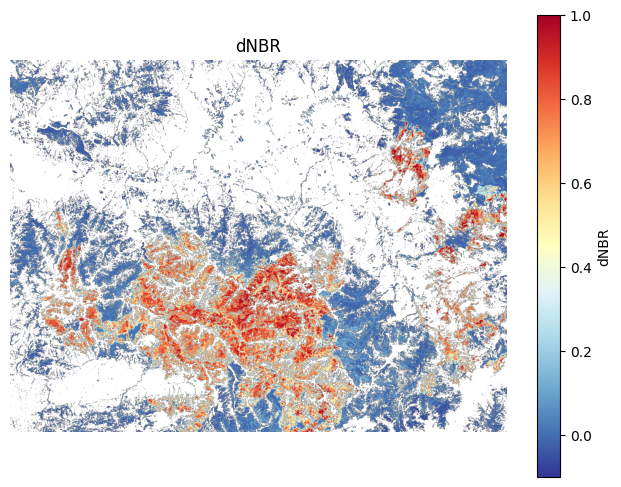

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def nbr(img):
    nir = img.sel(band="nir08")
    swir = img.sel(band="swir22")
    return (nir - swir) / (nir + swir)

dnbr = nbr(before) - nbr(after)

veg_before = before.sel(band="scl") == 4
after_scl = after.sel(band="scl")
clear_after = after_scl.notnull() & ~after_scl.isin([0, 1, 3, 8, 9, 10])
eligible = veg_before & clear_after

burned = (dnbr >= 0.27) & eligible
print("Eligible vegetation km2:", round(float(eligible.sum()) * 400 / 1e6, 2))
print("Burned km2:", round(float(burned.sum()) * 400 / 1e6, 2))

plt.figure(figsize=(8, 6))
plt.imshow(dnbr.where(eligible), cmap="RdYlBu_r", vmin=-0.1, vmax=1.0)
plt.colorbar(label="dNBR")
plt.title("dNBR")
plt.axis("off")
plt.show()

           class  area_km2
0            Low     29.37
1   Moderate-low     33.56
2  Moderate-high     63.34
3           High    111.08


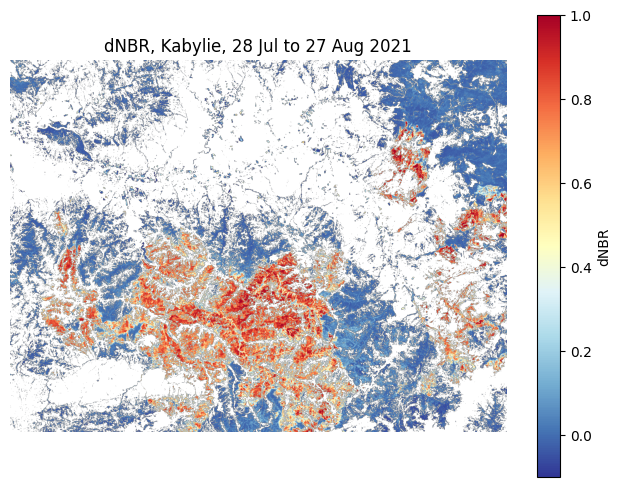

In [6]:
import os
import pandas as pd

os.makedirs("results", exist_ok=True)

classes = [("Low", 0.10, 0.27), ("Moderate-low", 0.27, 0.44),
           ("Moderate-high", 0.44, 0.66), ("High", 0.66, 10)]

rows = []
for name, lo, hi in classes:
    mask = (dnbr >= lo) & (dnbr < hi) & eligible
    rows.append({"class": name, "area_km2": round(float(mask.sum()) * 400 / 1e6, 2)})

table = pd.DataFrame(rows)
table.to_csv("results/severity_areas.csv", index=False)
print(table)

plt.figure(figsize=(8, 6))
plt.imshow(dnbr.where(eligible), cmap="RdYlBu_r", vmin=-0.1, vmax=1.0)
plt.colorbar(label="dNBR")
plt.title("dNBR, Kabylie, 28 Jul to 27 Aug 2021")
plt.axis("off")
plt.savefig("results/dnbr_map.png", dpi=150, bbox_inches="tight")
plt.show()